The InceptionV3 model is a deep convolutional neural network (CNN) designed for image classification tasks. It is part of the Inception family of models developed by Google and is known for its efficiency and high performance

In [1]:
import tensorflow as tf
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras import layers, models
from tensorflow.keras.layers import GlobalAveragePooling2D, Dense, Dropout, RandomFlip, RandomRotation, RandomZoom
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau
import matplotlib.pyplot as plt

In [2]:
# === 1. Setup ===
dataset_path = "../../../wheat_256px-dataset"
img_size = (256, 256)
batch_size = 32
num_classes = 5
seed = 42

# === 2. Load dataset with train/val/test split ===
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="training",
    seed=seed
)

val_test_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    dataset_path,
    image_size=img_size,
    batch_size=batch_size,
    validation_split=0.4,
    subset="validation",
    seed=seed
)

val_dataset = val_test_dataset.take(len(val_test_dataset) // 2)
test_dataset = val_test_dataset.skip(len(val_test_dataset) // 2)

# === 3. Data Augmentation ===
data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal_and_vertical"),
    RandomRotation(0.2),
    RandomZoom(0.2),
])

Found 19159 files belonging to 5 classes.
Using 11496 files for training.


2025-04-07 14:30:38.254019: I metal_plugin/src/device/metal_device.cc:1154] Metal device set to: Apple M1 Pro
2025-04-07 14:30:38.254059: I metal_plugin/src/device/metal_device.cc:296] systemMemory: 16.00 GB
2025-04-07 14:30:38.254072: I metal_plugin/src/device/metal_device.cc:313] maxCacheSize: 5.33 GB
2025-04-07 14:30:38.254094: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:305] Could not identify NUMA node of platform GPU ID 0, defaulting to 0. Your kernel may not have been built with NUMA support.
2025-04-07 14:30:38.254105: I tensorflow/core/common_runtime/pluggable_device/pluggable_device_factory.cc:271] Created TensorFlow device (/job:localhost/replica:0/task:0/device:GPU:0 with 0 MB memory) -> physical PluggableDevice (device: 0, name: METAL, pci bus id: <undefined>)


Found 19159 files belonging to 5 classes.
Using 7663 files for validation.


Found 19159 files belonging to 5 classes.
Using 11496 files for training.
Found 19159 files belonging to 5 classes.
Using 7663 files for validation.
Epoch 1/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 90s 234ms/step - accuracy: 0.3735 - loss: 1.8069 - val_accuracy: 0.6716 - val_loss: 0.9044 - learning_rate: 1.0000e-04
Epoch 2/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 221ms/step - accuracy: 0.5433 - loss: 1.3319 - val_accuracy: 0.7008 - val_loss: 0.8257 - learning_rate: 1.0000e-04
Epoch 3/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 82s 228ms/step - accuracy: 0.5955 - loss: 1.1883 - val_accuracy: 0.7047 - val_loss: 0.8478 - learning_rate: 1.0000e-04
Epoch 4/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 221ms/step - accuracy: 0.6179 - loss: 1.1079 - val_accuracy: 0.7464 - val_loss: 0.7082 - learning_rate: 1.0000e-04
Epoch 5/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 82s 227ms/step - accuracy: 0.6407 - loss: 1.0263 - val_accuracy: 0.7563 - val_loss: 0.6811 - learning_rate: 1.0000e-04
Epoch 6/60
360/360 ━━━━━━━━━━━━━━━━━━━━ 80s 223ms/step -

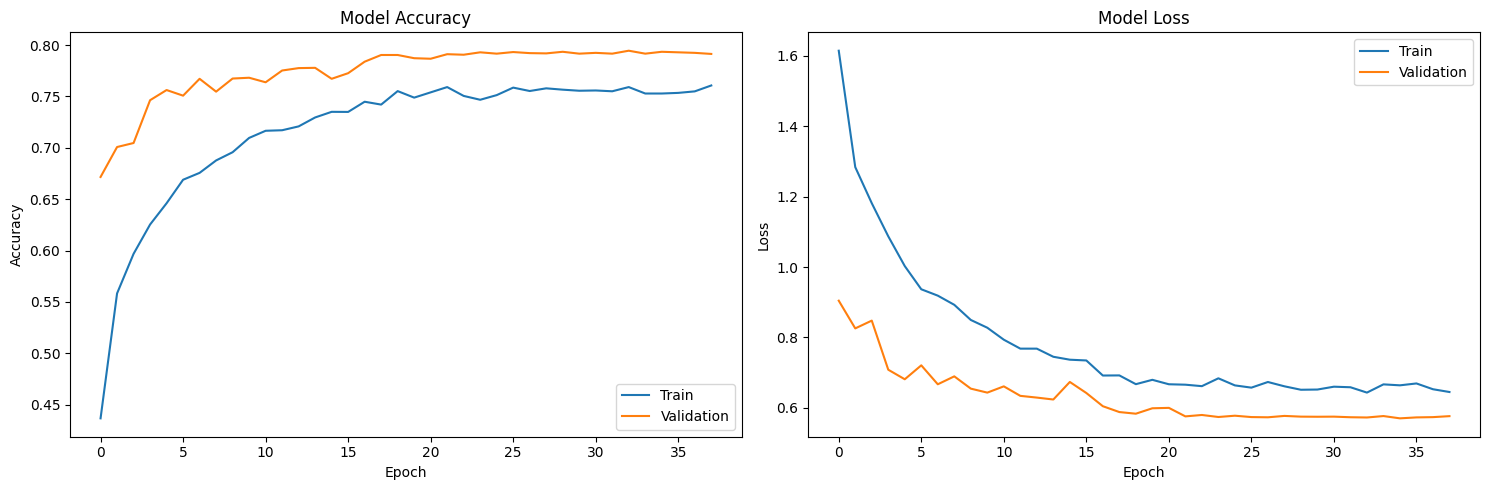

In [ ]:
# === 4. Load pretrained InceptionV3 with proper preprocessing ===
base_model = InceptionV3(
    weights='imagenet',
    include_top=False,
    input_shape=(256, 256, 3)
)
base_model.trainable = False  # Freeze initially

# === 5. Build Model with Inception-specific adjustments ===
inputs = tf.keras.Input(shape=(256, 256, 3))
x = data_augmentation(inputs)
x = tf.keras.applications.inception_v3.preprocess_input(x)  # Inception-specific preprocessing
x = base_model(x, training=False)
x = GlobalAveragePooling2D()(x)
x = Dense(512, activation='relu')(x)  # Larger dense layer for Inception
x = Dropout(0.6)(x)  # Slightly higher dropout
outputs = Dense(num_classes, activation='softmax')(x)

model = models.Model(inputs, outputs)

# === 6. Compile with adjusted learning rate ===
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# === 7. Enhanced Callbacks ===
callbacks = [
    EarlyStopping(patience=5, monitor='val_accuracy', restore_best_weights=True),
    ModelCheckpoint('inceptionv3_best.keras', monitor='val_accuracy', save_best_only=True),
    ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2)
]

# === 8. Training ===
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=60,  # Increased epochs
    callbacks=callbacks
)

# === 9. Evaluation ===
test_loss, test_acc = model.evaluate(test_dataset)
print(f"\nTest accuracy: {test_acc:.2%}")

# === 10. Enhanced Visualization ===
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Accuracy plot
ax1.plot(history.history['accuracy'], label='Train')
ax1.plot(history.history['val_accuracy'], label='Validation')
ax1.set_title('Model Accuracy')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.legend()

# Loss plot
ax2.plot(history.history['loss'], label='Train')
ax2.plot(history.history['val_loss'], label='Validation')
ax2.set_title('Model Loss')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.legend()

plt.tight_layout()
plt.show()

#### Prediction evaluation
Model Loading: The best model is loaded from the saved file (<best_model>.keras).
- Data Preparation: Test images and labels are extracted from the test dataset for evaluation.
- Predictions: The model predicts class probabilities for the test images, and the predicted labels are determined by selecting the class with the highest probability.
- Metrics Calculation: Key metrics such as accuracy, precision, recall, and F1-score are computed using the true and predicted labels.
- Classification Report: A detailed classification report is generated, showing precision, recall, and F1-score for each class.
- Confusion Matrix: A confusion matrix is plotted using Seaborn to visualize the model's performance across different classes.
- Sample Predictions: Random test samples are displayed with their true labels, predicted labels, and confidence scores to provide a qualitative assessment of the model's predictions.

2025-04-07 14:35:25.448847: W tensorflow/core/framework/local_rendezvous.cc:404] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


120/120 ━━━━━━━━━━━━━━━━━━━━ 27s 174ms/step

Classification Report:
              precision    recall  f1-score   support

  brown_rust       0.70      0.85      0.77       498
     healthy       0.71      0.85      0.77       437
      mildew       0.95      0.57      0.71       604
    septoria       0.86      0.83      0.84      1399
 yellow_rust       0.73      0.79      0.76       885

    accuracy                           0.79      3823
   macro avg       0.79      0.78      0.77      3823
weighted avg       0.80      0.79      0.79      3823


Additional Metrics:
Accuracy: 78.68%
Precision: 80.34%
Recall: 78.68%
F1-Score: 78.56%


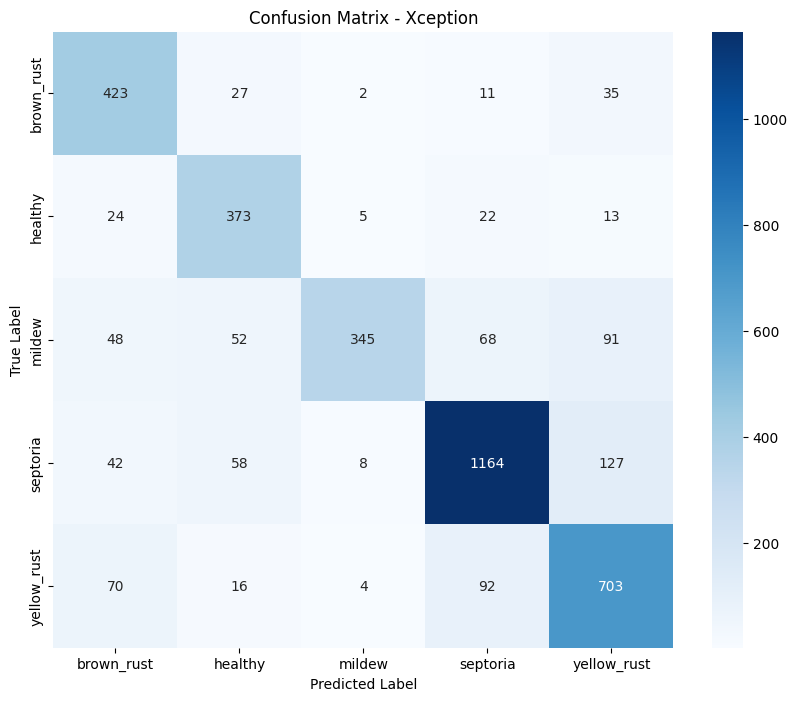

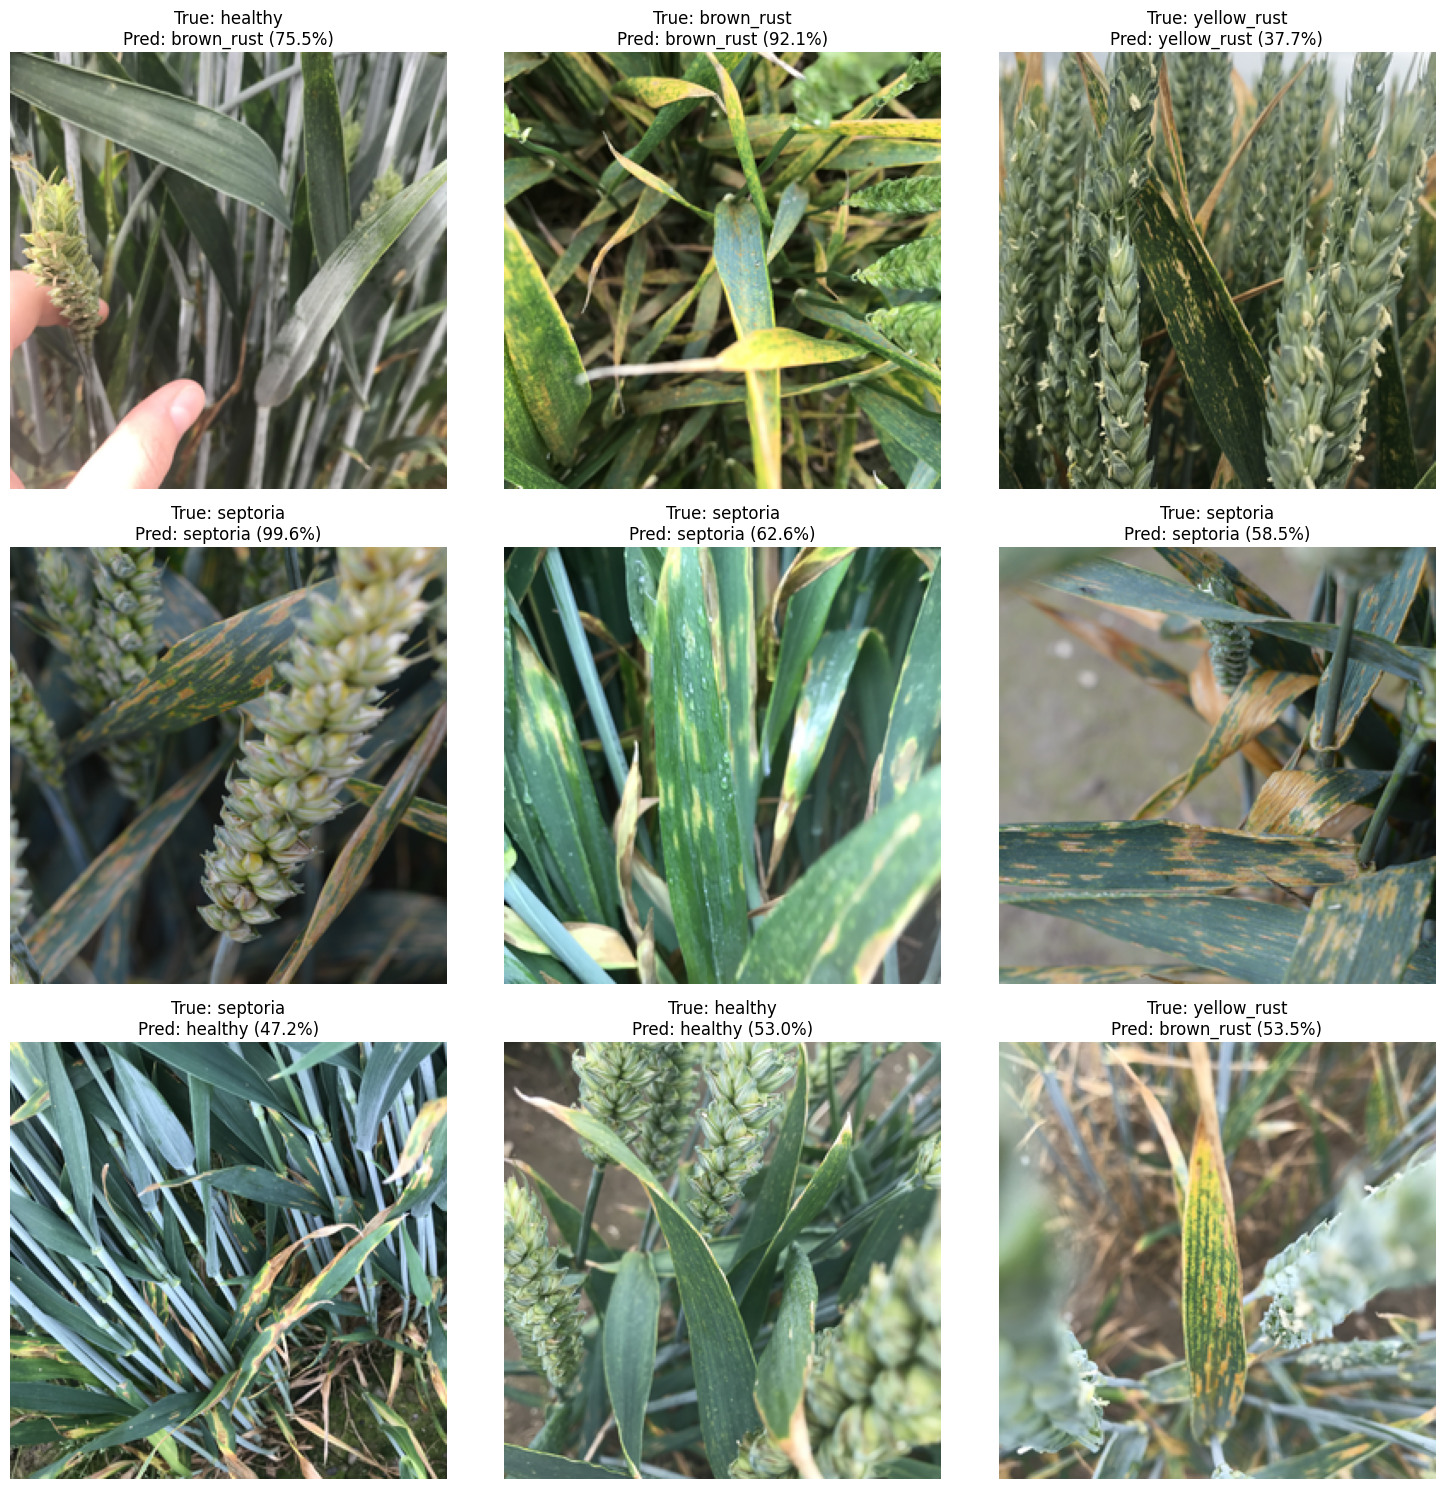

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score
import seaborn as sns

model = tf.keras.models.load_model('inceptionv3_best.keras')
class_names = train_dataset.class_names

test_images, test_labels = [], []
for img, lbl in test_dataset.unbatch():
    test_images.append(img.numpy())
    test_labels.append(lbl.numpy())

test_images = np.array(test_images)
test_labels = np.array(test_labels)

# predictions
predictions = model.predict(test_images, verbose=1)
predicted_labels = np.argmax(predictions, axis=1)

# metrics
accuracy = accuracy_score(test_labels, predicted_labels)
precision = precision_score(test_labels, predicted_labels, average='weighted')
recall = recall_score(test_labels, predicted_labels, average='weighted')
f1 = f1_score(test_labels, predicted_labels, average='weighted')

print("\nClassification Report:")
print(classification_report(test_labels, predicted_labels, target_names=class_names))

print("\nAdditional Metrics:")
print(f"Accuracy: {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1-Score: {f1:.2%}")

plt.figure(figsize=(10, 8))
cm = confusion_matrix(test_labels, predicted_labels)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)
plt.title('Confusion Matrix - Xception')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

plt.figure(figsize=(15, 15))
for i in range(9):  # Show 9 random samples
    ax = plt.subplot(3, 3, i+1)
    plt.imshow(test_images[i].astype('uint8'))  # Assumes RGB images
    true_label = class_names[test_labels[i]]
    pred_label = class_names[predicted_labels[i]]
    confidence = np.max(predictions[i]) * 100
    plt.title(f"True: {true_label}\nPred: {pred_label} ({confidence:.1f}%)")
    plt.axis('off')
plt.tight_layout()
plt.show()